In [3]:
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit
from scipy.stats import norm
from scipy.stats import moyal

In [4]:
PLOTS_DIR = Path("plots")
PLOTS_DIR.mkdir(exist_ok=True)


def save_plot(filename=None):
    figure = plt.gcf()
    if filename is None:
        title = figure.axes[0].get_title() if figure.axes else "plot"
        filename = re.sub(
            r"[^a-zA-Z0-9_-]+",
            "_",
            title
        ).strip("_").lower()
        filename = filename or "plot"

    figure.savefig(
        PLOTS_DIR / f"{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )

In [5]:
CSV_PATH = "data_1000e.csv"

COLUMN_NAMES = [
    "RunID",
    "EventID",
    "TrackID",
    "Hit",
    "GlobalTime",
    "TimeSinceZero",
    "TrackLenght",
    "PhotonEnergy",
    "PhotonFlightTime",
    "PhotonCreationTime",
    "Process",
    "SideReflections"
]

DTYPES = {
    "RunID": "int32",
    "EventID": "int32",
    "trackID": "int32",
    "hit": "category",
    "globaltime": "float64",
    "timesinceelectronhit": "float64",
    "trackLength": "float32",
    "photonEnergy": "float32",
    "photonFlightTime": "float32",
    "photonCreationTime": "float32",
    "creatorProcess": "category",
    "sideReflections": "int32",
}

data = pd.read_csv(CSV_PATH, comment="#", header=None, names=COLUMN_NAMES, dtype=DTYPES)

counts_data = len(data)
counts_events = data['EventID'].nunique()

data["WavelengthNM"] = (1239.841984 / data["PhotonEnergy"])

print(f"{counts_data:,} Photon-Treffer geladen, {counts_events:,} Events")
data.head()

1,994,560 Photon-Treffer geladen, 1,000 Events


,RunID,EventID,TrackID,Hit,GlobalTime,TimeSinceZero,TrackLenght,PhotonEnergy,PhotonFlightTime,PhotonCreationTime,Process,SideReflections,WavelengthNM
0,0,0,3313,bottom,3.551660,3.224770,38.1120,3.57951,0.143811,3.080960,Scintillation,4,346.371985
1,0,0,3312,bottom,0.572754,0.245865,49.5436,3.43263,0.184424,0.061441,Scintillation,3,361.193016
2,0,0,3310,bottom,3.268410,2.941520,50.9576,3.45716,0.183435,2.758080,Scintillation,8,358.630201
3,0,0,3304,bottom,0.777186,0.450297,48.7501,3.36494,0.171384,0.278913,Scintillation,6,368.458868
4,0,0,3303,bottom,3.631900,3.305010,35.6786,3.56211,0.126462,3.178550,Scintillation,1,348.063924


In [6]:
# masks
mask_process_scintillation = data["Process"] == "Scintillation"
mask_process_cerenkov = data["Process"] == "Cerenkov"

mask_hit_top = data["Hit"] == "top"
mask_hit_bottom = data["Hit"] == "bottom"

# all data
data_all = data.copy()

# only Scintillation
data_all_scintillation = data[
    mask_process_scintillation
].copy()

# only Cerenkov
data_all_cerenkov = data[
    mask_process_cerenkov
].copy()

# only top data all
data_all_top = data[
    mask_hit_top
].copy()

# only top data scintillation
data_all_top_scintillation = data[
    (mask_hit_top)
    &
    (mask_process_scintillation)
].copy()

# only top data cerenkov
data_all_top_cerenkov = data[
    (mask_hit_top)
    &
    (mask_process_cerenkov)
].copy()

# only bottom data all
data_all_bottom = data[
    mask_hit_bottom
].copy()

# only bottom data scintillation
data_all_bottom_scintillation = data[
    (mask_hit_bottom)
    &
    (mask_process_scintillation)
].copy()

# only top data cerenkov
data_all_bottom_cerenkov = data[
    (mask_hit_bottom)
    &
    (mask_process_cerenkov)
].copy()

# arrival times
data_arr_times_all = (
    data_all["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_all_scintillation = (
    data_all_scintillation["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_all_cerenkov = (
    data_all_cerenkov["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_all_top = (
    data_all_top["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_all_bottom = (
    data_all_bottom["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_top_scintillation = (
    data_all_top_scintillation["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_top_cerenkov = (
    data_all_top_cerenkov["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_bottom_scintillation = (
    data_all_bottom_scintillation["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_bottom_cerenkov = (
    data_all_bottom_cerenkov["TimeSinceZero"].dropna().to_numpy()
)

data_wavelength_all = (
    data_all["WavelengthNM"].dropna().to_numpy()
)

data_wavelength_scintillation = (
    data_all_scintillation["WavelengthNM"].dropna().to_numpy()
)

data_wavelength_cerenkov = (
    data_all_cerenkov["WavelengthNM"].dropna().to_numpy()
)

# creat groups for every event: access via event17 = events[17]
data_events = {
    event_id: event_data.copy()
    for event_id, event_data in data.groupby("EventID")
}

print("Data loaded!")

Data loaded!


In [7]:
def scintillation_pluse_shape(t, A, t0, tau_rise, tau_fall, background):
    t = np.asarray(t, dtype=float)
    dt = t - t0
    shape = np.zeros_like(dt)
    mask = dt > 0
    shape[mask] = (1.0 - np.exp(-dt[mask] / tau_rise)) * np.exp(-dt[mask] / tau_fall)
    return A * shape + background

def scintillation_pluse_shape_maximum(t_0, t_rise, t_fall):
    return t_0 + (t_rise * np.log(1.0 + t_fall / t_rise))

In [8]:
# Fit-Funktion für einen Datensatz
def fit_dataset(
    times,
    bins=1000,
    fit_range=(0, 10)
):

    counts, bin_edges = np.histogram(
        times,
        bins=bins,
        range=fit_range
    )

    bin_centers = 0.5 * (
        bin_edges[:-1] + bin_edges[1:]
    )

    # Poisson errors
    sigma = np.sqrt(
        np.maximum(counts, 1)
    )

    # amplitude, t0, t_rise, t_fall, background
    initial_values = [
        counts.max(),
        0.1,
        0.350,
        1.600,
        0.0
    ]

    bounds = (
        [
            0.0,       # amplitude
            -1.0,      # t0
            0.001,     # rise
            0.05,      # fall
            0.0        # background
        ],
        [
            np.inf,
            2.0,
            10.0,
            20.0,
            np.inf
        ]
    )

    fit_parameters, covariance = curve_fit(
        scintillation_pluse_shape,
        bin_centers,
        counts,
        p0=initial_values,
        sigma=sigma,
        absolute_sigma=True,
        bounds=bounds,
        maxfev=50000
    )

    errors = np.sqrt(
        np.diag(covariance)
    )

    return (
        counts,
        bin_edges,
        bin_centers,
        fit_parameters,
        errors
    )

In [9]:
def fit_single_event(times, bins, fit_range):

    (
        counts_single_event,
        edges_single_event,
        centers_single_event,
        params_single_event,
        errors_single_event
    ) = fit_dataset(
        times,
        bins=bins,
        fit_range=fit_range
    )

    return params_single_event, errors_single_event

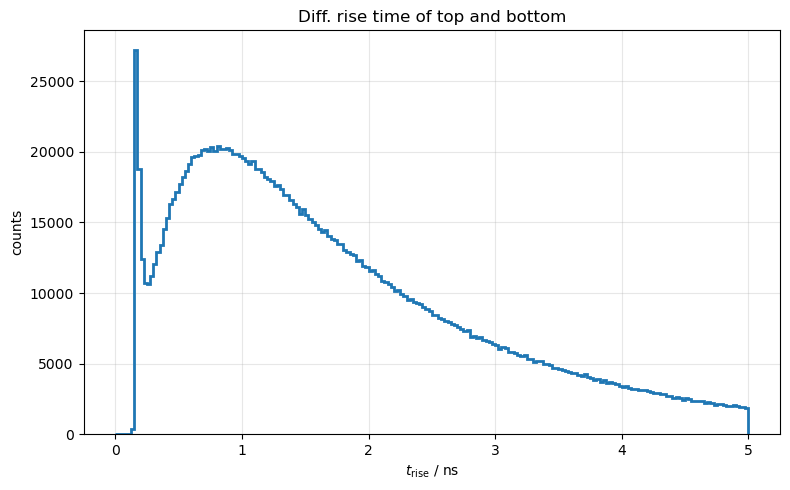

In [10]:
plt.figure(figsize=(8, 5))

plt.hist(
    data_arr_times_all,
    bins=200,
    histtype="step",
    range=(0, 5),
    linewidth=2
)

plt.xlabel(r"$t_\mathrm{rise}$ / ns")
plt.ylabel("counts")
plt.title("Diff. rise time of top and bottom")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
event_fits = []

bins = 200
fit_range = (0, 10)

for event_id, event_data in data_events.items():

    # nur Scintillation-Photonen dieses Events
    event_scint = event_data[
        event_data["Process"] == "Scintillation"
    ]

    times = (
        event_scint["TimeSinceZero"]
        .dropna()
        .to_numpy()
    )

    try:
        # Fit durchführen
        params, errors = fit_single_event(
            times,
            bins,
            fit_range
        )

        A, t0, tau_rise, tau_fall, background = params

        (
            A_err,
            t0_err,
            tau_rise_err,
            tau_fall_err,
            background_err
        ) = errors

        # Peak-Zeit berechnen
        t_peak = scintillation_pluse_shape_maximum(
            t0,
            tau_rise,
            tau_fall
        )

        # Ergebnis speichern
        event_fits.append({
            "EventID": event_id,
            "NPhotons": len(times),

            "A": A,
            "A_error": A_err,

            "t0": t0,
            "t0_error": t0_err,

            "tau_rise": tau_rise,
            "tau_rise_error": tau_rise_err,

            "tau_fall": tau_fall,
            "tau_fall_error": tau_fall_err,

            "background": background,
            "background_error": background_err,

            "t_peak": t_peak
        })

    except RuntimeError:
        print(f"Fit failed for Event {event_id}")

In [12]:
event_fits = []

bins = 200
fit_range = (0, 10)

for event_id, event_data in data_events.items():

    # Top: only Scint
    event_scint_top = event_data[
        (event_data["Process"] == "Scintillation")
        &
        (event_data["Hit"] == "top")
    ]
    
    times_top = (
        event_scint_top["TimeSinceZero"]
        .dropna()
        .to_numpy()
    )
    
    # bottom: only Scint
    event_scint_bottom = event_data[
        (event_data["Process"] == "Scintillation")
        &
        (event_data["Hit"] == "bottom")
    ]
    
    times_bottom = (
        event_scint_bottom["TimeSinceZero"]
        .dropna()
        .to_numpy()
    )
    
    # fit for top and bottom sep.
    
    params_top, errors_top = fit_single_event(
        times_top,
        bins,
        fit_range
    )
    
    params_bottom, errors_bottom = fit_single_event(
        times_bottom,
        bins,
        fit_range
    )
    
    A_top, t0_top, tau_rise_top, tau_fall_top, background_top = params_top
    
    (
        A_err_top,
        t0_err_top,
        tau_rise_err_top,
        tau_fall_err_top,
        background_err_top
    ) = errors_top
    
    A_bottom, t0_bottom, tau_rise_bottom, tau_fall_bottom, background_bottom = params_bottom
    
    (
        A_err_bottom,
        t0_err_bottom,
        tau_rise_err_bottom,
        tau_fall_err_bottom,
        background_err_bottom
    ) = errors_bottom
    
    
    # save results
    event_fits.append({
        "EventID": event_id,
        
        "NPhotons_top": len(times_top),
        "A_top": A_top,
        "A_error_top": A_err_top,
        "t0_top": t0_top,
        "t0_error_top": t0_err_top,
        "tau_rise_top": tau_rise_top,
        "tau_rise_error_top": tau_rise_err_top,
        "tau_fall_top": tau_fall_top,
        "tau_fall_error_top": tau_fall_err_top,
        "background_top": background_top,
        "background_error_top": background_err_top,
        
        "NPhotons_bottom": len(times_bottom),
        "A_bottom": A_bottom,
        "A_error_bottom": A_err_bottom,
        "t0_bottom": t0_bottom,
        "t0_error_bottom": t0_err_bottom,
        "tau_rise_bottom": tau_rise_bottom,
        "tau_rise_error_bottom": tau_rise_err_bottom,
        "tau_fall_bottom": tau_fall_bottom,
        "tau_fall_error_bottom": tau_fall_err_bottom,
        "background_bottom": background_bottom,
        "background_error_bottom": background_err_bottom,
    })

In [22]:
# calculate t_rise diff. for top and bottom

t_rise_diff_events = []

for event in event_fits:
    
    t_rise_diff = event['tau_rise_top'] - event['tau_rise_bottom']
    
    t_rise_diff_events.append(t_rise_diff)

In [23]:
t_rise_diff_events_pd = pd.DataFrame(t_rise_diff_events)

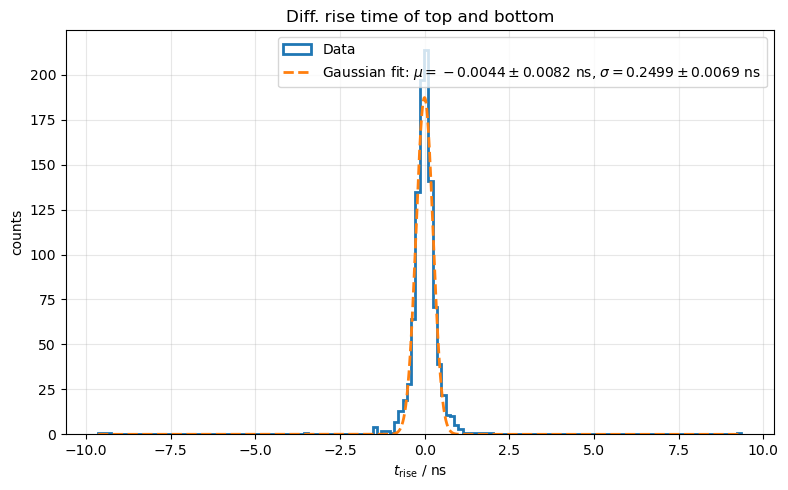

In [27]:
def gauss(x, A, mu, sigma):
    return A * np.exp(-0.5 * ((x - mu) / sigma) ** 2)


t_rise_diff_values = t_rise_diff_events_pd.to_numpy(dtype=float).ravel()
t_rise_diff_values = t_rise_diff_values[np.isfinite(t_rise_diff_values)]

counts, bin_edges = np.histogram(t_rise_diff_values, bins=150)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
bin_width = bin_edges[1] - bin_edges[0]

# Startwerte aus Median und MAD, damit Ausreißer den Start nicht verschieben
median = np.median(t_rise_diff_values)
mad_sigma = 1.4826 * np.median(np.abs(t_rise_diff_values - median))

popt, pcov = curve_fit(
    gauss,
    bin_centers,
    counts,
    p0=[counts.max(), median, mad_sigma],
    sigma=np.sqrt(np.maximum(counts, 1)),
    absolute_sigma=True
)
gauss_A, gauss_mean, gauss_sigma = popt
gauss_sigma = abs(gauss_sigma)
gauss_mean_err, gauss_sigma_err = np.sqrt(np.diag(pcov))[1:]

plt.figure(figsize=(8, 5))

plt.hist(
    t_rise_diff_values,
    bins=bin_edges,
    histtype="step",
    linewidth=2,
    label="Data"
)

fit_x = np.linspace(bin_edges[0], bin_edges[-1], 5000)

plt.plot(
    fit_x,
    gauss(fit_x, *popt),
    linewidth=2,
    linestyle="--",
    label=(
        rf"Gaussian fit: $\mu={gauss_mean:.4f}\pm{gauss_mean_err:.4f}$ ns, "
        rf"$\sigma={gauss_sigma:.4f}\pm{gauss_sigma_err:.4f}$ ns"
    )
)

plt.xlabel(r"$t_\mathrm{rise}$ / ns")
plt.ylabel("counts")
plt.title("Diff. rise time of top and bottom")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()